In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Service Count Analysis
# Calculate number of services each customer subscribes to

service_cols = ['PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
                'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

def count_services(row):
    count = 0
    for col in service_cols:
        val = row[col]
        if val == 'Yes':
            count += 1
    return count

df['ServiceCount'] = df.apply(count_services, axis=1)

print("="*80)
print("SERVICE COUNT vs CHURN RATE")
print("="*80)

service_churn = pd.crosstab(df['ServiceCount'], df['Churn'], normalize='index') * 100
print(service_churn['Yes'])
print()

# Customers with 0 services are those with No InternetService AND No PhoneService
zero_services = df[df['ServiceCount'] == 0]
print(f"Customers with 0 counted 'Yes' services: {len(zero_services)}")
print(f"  - Their churn rate: {(zero_services['Churn'] == 'Yes').mean() * 100:.1f}%")
print(f"Customers with 1-2 services:")
print(f"  - Churn rate: {(df[(df['ServiceCount'] >= 1) & (df['ServiceCount'] <= 2)]['Churn'] == 'Yes').mean() * 100:.1f}%")
print(f"Customers with 3+ services:")
print(f"  - Churn rate: {(df[df['ServiceCount'] >= 3]['Churn'] == 'Yes').mean() * 100:.1f}%")

# Visualize service count vs churn using pivot table
grouped = df.groupby(['ServiceCount', 'Churn']).size().reset_index(name='count')
grouped['churn_rate'] = grouped.groupby('ServiceCount')['count'].transform(lambda x: x / x.sum() * 100)
pivot = grouped.pivot(index='ServiceCount', columns='Churn', values='churn_rate')

plt.figure(figsize=(10, 5))
pivot['Yes'].plot(kind='bar', color='#ff6b6b', alpha=0.7, label='Churned')
pivot['No'].plot(kind='bar', color='#4ecdc4', alpha=0.7, label='Retained')
plt.title("Churn Rate by Number of Services Subscribed")
plt.xlabel("Number of Services")
plt.ylabel("Churn Rate (%)")
plt.legend(title='Churn')
plt.xticks(rotation=0)
plt.show()

print("\nBusiness Insight: Customers with fewer services are more likely to churn.")
print("Bundling services may be an effective retention strategy.")

In [6]:
# Load the cleaned customer churn dataset

df = pd.read_csv("../data/processed/cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (7043, 21)


In [7]:
# Display the first 5 rows

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,False,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,False,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,False,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,False,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,False,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
# Check column names, data types, and non-null values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   bool   
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
# Statistical summary of numerical columns

df.describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2281.916928
std,24.559481,30.090047,2265.270398
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,402.225000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [10]:
# Count customers in each churn category

print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [12]:
# Calculate churn percentage

print(df["Churn"].value_counts(normalize=True) * 100)


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


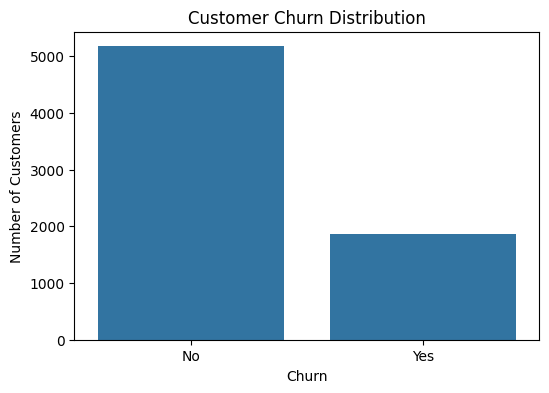

In [13]:
# Visualize the churn distribution

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [14]:
# Churn rate by contract type

churn_by_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_contract)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


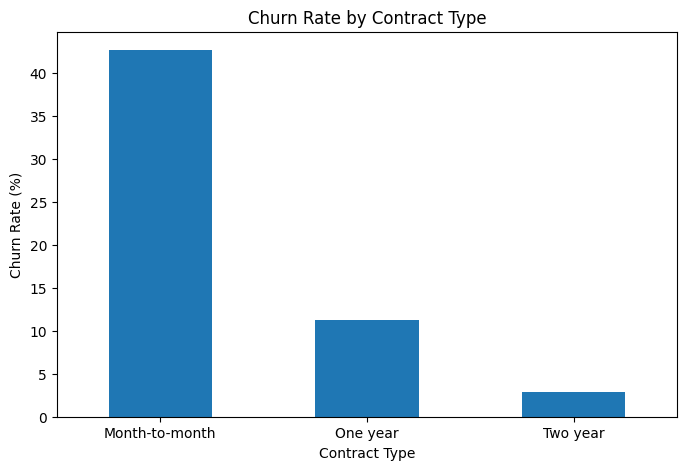

In [15]:
# Visualize churn rate by contract type

churn_by_contract["Yes"].sort_values(ascending=False).plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

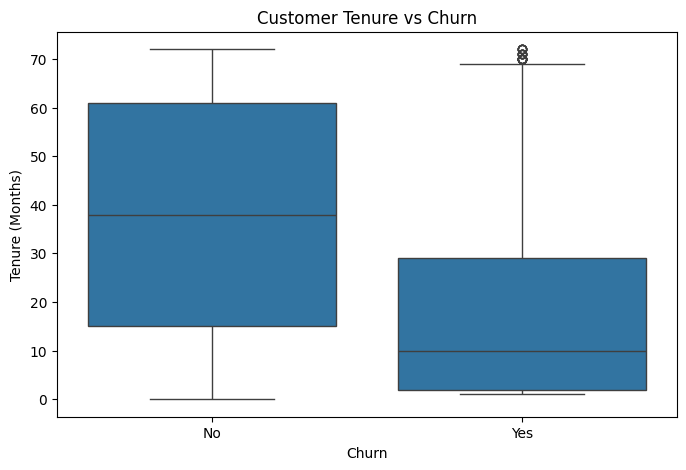

In [16]:
# Compare customer tenure for churned vs non-churned customers

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

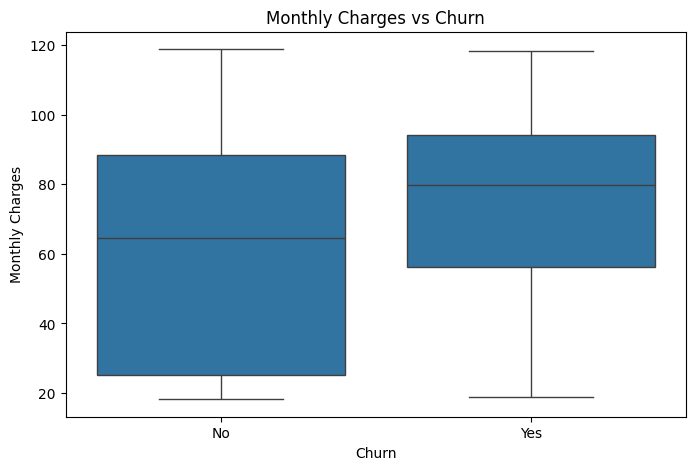

In [17]:
# Compare monthly charges for churned vs non-churned customers

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [18]:
# Calculate churn rate by internet service

churn_by_internet = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_internet)


Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


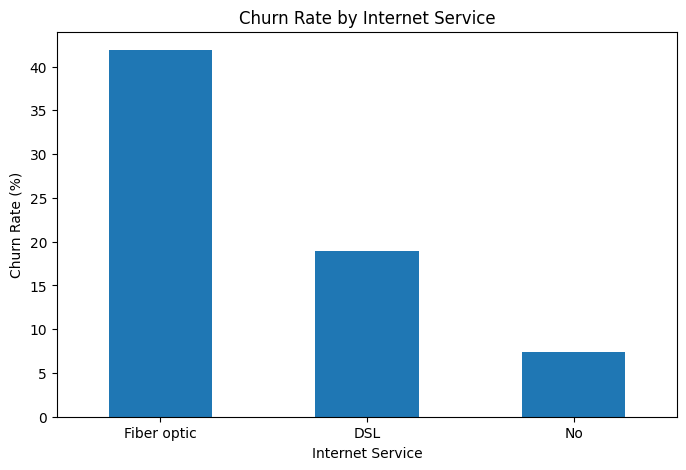

In [19]:
# Visualize churn rate by internet service

churn_by_internet["Yes"].sort_values(ascending=False).plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

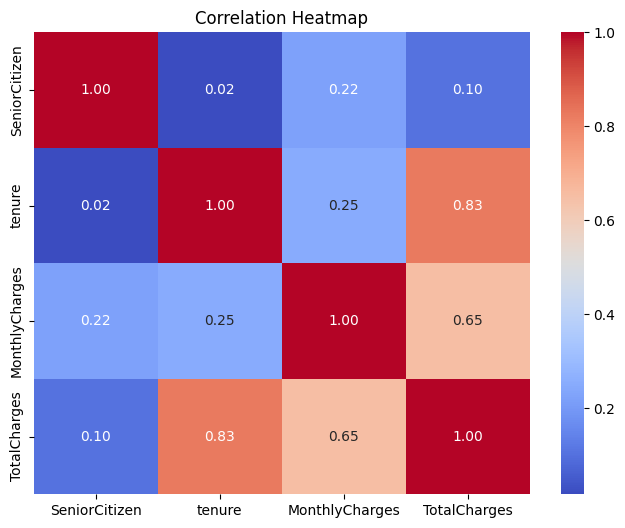

In [20]:
# Correlation between numerical variables

numeric_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [21]:
# Churn rate by payment method

churn_by_payment = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_payment)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


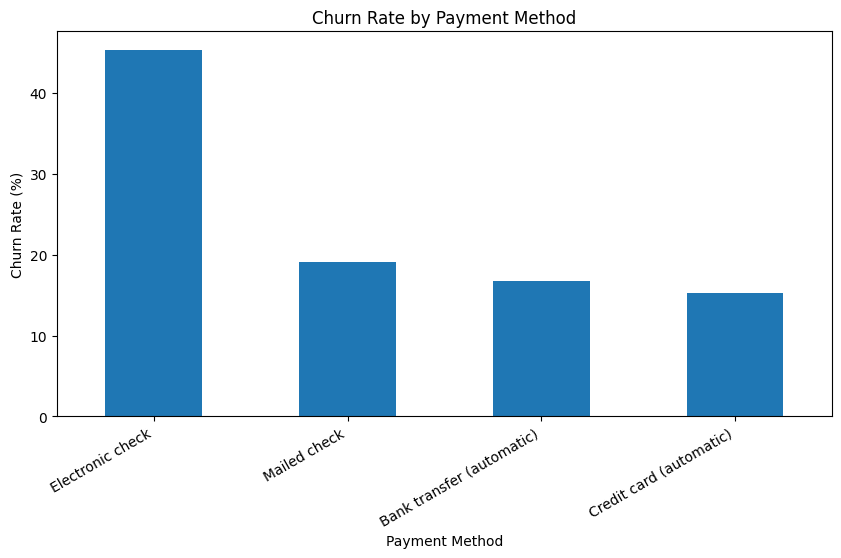

In [22]:
# Visualize churn rate by payment method

churn_by_payment["Yes"].sort_values(ascending=False).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30, ha="right")

plt.show()


In [23]:
# Churn rate by paperless billing

churn_by_billing = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_billing)

Churn                    No        Yes
PaperlessBilling                      
No                83.669916  16.330084
Yes               66.434908  33.565092


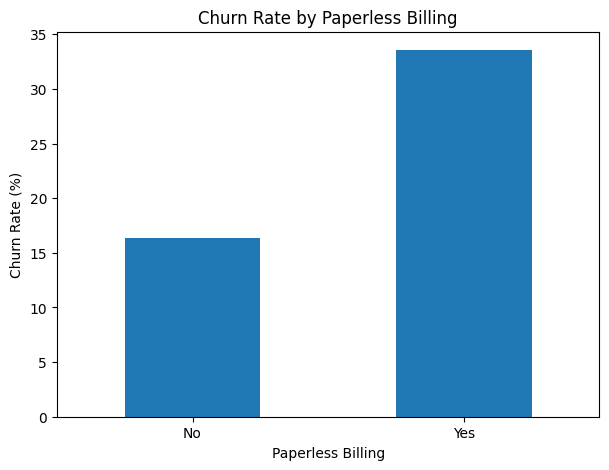

In [24]:
# Visualize churn rate by paperless billing

churn_by_billing["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [25]:
# Churn rate by senior citizen status

churn_by_senior = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

churn_by_senior.index = ["Non-Senior", "Senior"]

print(churn_by_senior)

Churn              No        Yes
Non-Senior  76.393832  23.606168
Senior      58.318739  41.681261


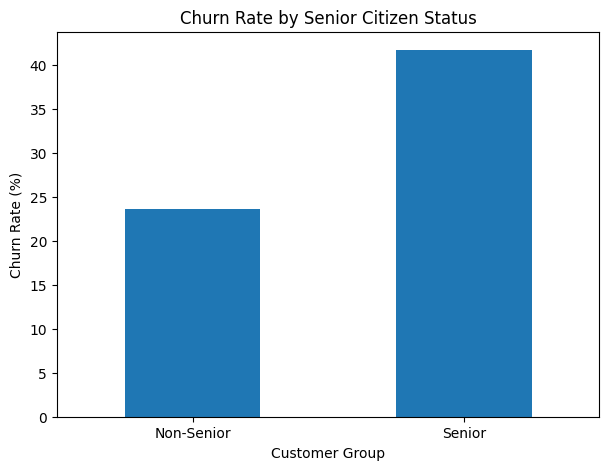

In [26]:
# Visualize churn rate by senior citizen status

churn_by_senior["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Customer Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [ ]:
# Tenure Buckets Analysis
# Categorize customers into tenure groups for deeper insights

df['TenureGroup'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72], 
                           labels=['0-12 months', '13-24 months', '25-48 months', '49+ months'])

tenure_churn = pd.crosstab(df['TenureGroup'], df['Churn'], normalize='index') * 100

print("="*80)
print("TENURE BUCKETS vs CHURN RATE")
print("="*80)
print(tenure_churn['Yes'].sort_values(ascending=False))
print()
print("Key Finding: Customers with 0-12 months tenure have the highest churn rate.")
print("This suggests early-stage customers are most vulnerable to leaving.")

# Visualize tenure bucket churn
plt.figure(figsize=(8, 5))
tenure_churn['Yes'].sort_values(ascending=False).plot(kind='bar', color='#ff6b6b')
plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group (Months)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

print("\nBusiness Insight: Focus retention efforts on customers in first year.")